# Task 1 — Preattentive attributes and visual search
**CLO1 — how the human brain processes visual information.**

Data: `stimuli_search.csv` (90 trials, one row per on-screen item). Every chart is built with `fig, ax = plt.subplots()`.

**Honesty note.** Steps 2–4 need a real reader. The experiment runner is written and ready (Step 2), but the
results cells only produce output once `search_results.csv` exists. Nothing in this notebook is simulated.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# find the data folder whether the notebook sits in assignments/ or one level up
DATA = next(p for p in (Path("data"), Path("assignments/data"), Path("week2/assignments/data")) if p.exists())

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
})
GREY, RED, BLUE = "#bbbbbb", "#ee6677", "#4477aa"

search = pd.read_csv(DATA / "stimuli_search.csv")
print(search.shape, "->", search.trial.nunique(), "trials")
search.head()

(2430, 10) -> 90 trials


,trial,condition,set_size,target_present,item_index,x,y,colour,shape,is_target
0,1,colour,9,yes,0,0.2935,1.4610,blue,circle,no
1,1,colour,9,yes,1,0.2649,2.3593,blue,circle,no
2,1,colour,9,yes,2,1.5027,2.2633,blue,circle,no
3,1,colour,9,yes,3,1.3494,1.5749,blue,circle,no
4,1,colour,9,yes,4,2.5225,2.3602,blue,circle,no


## Step 1 — Render the trials
One function draws any trial on a given `ax`: items at `x`/`y`, coloured and shaped by the columns, no axes, no ticks, no title.
Squares use the same marker area as circles, so size is not a hidden extra cue.

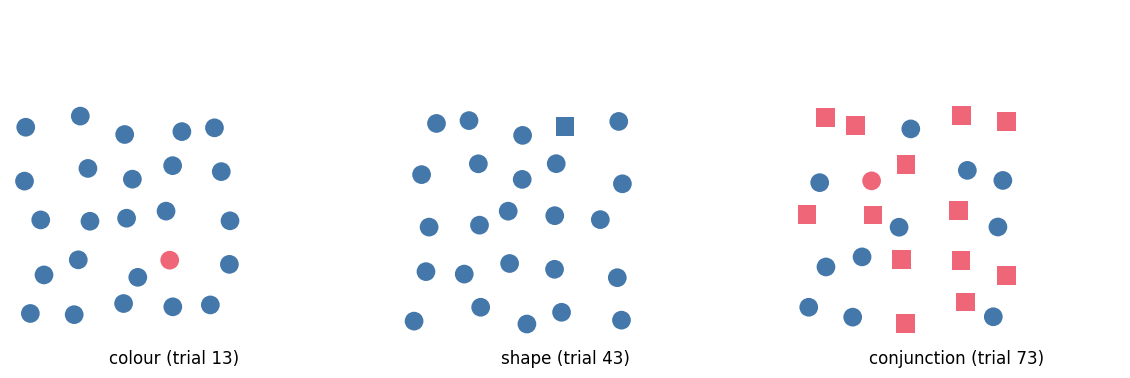

In [2]:
COL = {"red": RED, "blue": BLUE}
MARK = {"circle": "o", "square": "s"}

def draw_trial(ax, trial):
    d = search[search.trial == trial]
    for (colour, shape), g in d.groupby(["colour", "shape"]):
        ax.scatter(g.x, g.y, s=150, c=COL[colour], marker=MARK[shape], edgecolors="none")
    ax.set_xlim(0, 7); ax.set_ylim(0, 7)
    ax.set_aspect("equal")
    ax.axis("off")

# verification: one target-present trial per condition at set_size = 25
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, cond in zip(axes, ["colour", "shape", "conjunction"]):
    t = search[(search.condition == cond) & (search.set_size == 25) & (search.target_present == "yes")].trial.iloc[0]
    draw_trial(ax, t)
    ax.text(0.5, -0.04, f"{cond} (trial {t})", transform=ax.transAxes, ha="center", va="top", fontsize=11)
fig.savefig("task1_step1_render_check.png", dpi=150, bbox_inches="tight")
plt.show()

**What the eye does.** In the left panel the red circle is found without hunting: hue differs from every distractor, so a
single colour feature map lights up at one location. In the middle panel the square is also found quickly — form (shape) is a
second preattentive feature. In the right panel nothing pops. Every distractor shares one feature with the target, so neither
the "red" map nor the "circle" map isolates it. You have to inspect items one at a time. (Look for the red circle in the right
panel yourself before checking the data: `is_target == "yes"`.)

## Step 2 — Run the experiment on a real person

**Design.** The brief says "two per (condition × set_size) cell" for 18 trials, but 3 conditions × 5 set sizes × 2 would be 30.
To land on 18 I use **3 conditions × 3 set sizes (9, 25, 49) × {target present, target absent} = 18 trials**, one trial per
cell. Change `SET_SIZES_USED` to `[9, 16, 25, 36, 49]` if you want a 30-trial version with five points per line.

**Procedure.** Trials are blocked by condition. Before each block the participant is told the target (so it is never revealed
mid-block). Trial order inside a block is shuffled. Response time is `time.perf_counter()` from the moment the display appears
until they answer `y`/`n` (so it includes typing latency, which is the same constant for every condition and cancels in the slope).

Set `RUN_EXPERIMENT = True`, run the cell, and hand the laptop to your participant. Do **not** run it yourself and invent answers:
the marking guide penalises noiseless or implausible results.

In [3]:
import time
from IPython.display import clear_output, display

SET_SIZES_USED = [9, 25, 49]
PARTICIPANT = "a classmate"        # first name or "a classmate"
RUN_EXPERIMENT = False             # <- flip to True when a real person is sitting there
TARGET_TEXT = {"colour": "a RED CIRCLE among blue circles",
               "shape": "a BLUE SQUARE among blue circles",
               "conjunction": "a RED CIRCLE among red squares and blue circles"}

rng = np.random.default_rng(7)     # only used to choose trials and their order; the stimuli seed is untouched
cells = (search.drop_duplicates("trial")
         .query("set_size in @SET_SIZES_USED")
         .groupby(["condition", "set_size", "target_present"]))
chosen = pd.concat([g.sample(1, random_state=int(rng.integers(1e6))) for _, g in cells])
chosen = chosen[["trial", "condition", "set_size", "target_present"]].reset_index(drop=True)
print(len(chosen), "trials selected")
chosen

18 trials selected


,trial,condition,set_size,target_present
0,4,colour,9,no
1,3,colour,9,yes
2,17,colour,25,no
3,15,colour,25,yes
4,30,colour,49,no
5,25,colour,49,yes
6,65,conjunction,9,no
7,61,conjunction,9,yes
8,77,conjunction,25,no
9,73,conjunction,25,yes


In [4]:
def run_experiment():
    rows = []
    conds = list(rng.permutation(["colour", "shape", "conjunction"]))
    for cond in conds:
        clear_output(wait=True)
        print(f"BLOCK: {cond}\nTarget: {TARGET_TEXT[cond]}.")
        input("Press Enter when ready... ")
        block = chosen[chosen.condition == cond].sample(frac=1, random_state=int(rng.integers(1e6)))
        for _, r in block.iterrows():
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(5, 5))
            draw_trial(ax, r.trial)
            display(fig); plt.close(fig)
            t0 = time.perf_counter()
            ans = ""
            while ans not in ("y", "n"):
                ans = input("Is the target there? (y/n): ").strip().lower()
            rt_ms = (time.perf_counter() - t0) * 1000
            rows.append(dict(participant=PARTICIPANT, trial=r.trial, condition=cond, set_size=r.set_size,
                             target_present=r.target_present, response=ans,
                             correct=(ans == "y") == (r.target_present == "yes"), rt_ms=round(rt_ms, 1)))
    out = pd.DataFrame(rows)
    out.to_csv("search_results.csv", index=False)
    clear_output(wait=True)
    print("Saved search_results.csv")
    return out

if RUN_EXPERIMENT:
    results = run_experiment()

## Step 3 — Response time against set size (target-present trials only)
Target-absent trials are kept out on purpose: the reader has to convince themselves nothing is there, so they are slower even in
parallel conditions and would blur the slope.

In [5]:
RESULTS = Path("search_results.csv")
CONDS = ["colour", "shape", "conjunction"]
STYLE = {"colour": dict(color=GREY, marker="o"), "shape": dict(color="#888888", marker="s"), "conjunction": dict(color=RED, marker="^")}

if RESULTS.exists():
    res = pd.read_csv(RESULTS)
    present = res[(res.target_present == "yes") & (res.correct)]
    mean_rt = present.groupby(["condition", "set_size"]).rt_ms.mean().reset_index()

    fig, ax = plt.subplots(figsize=(8, 5))
    for cond in CONDS:
        d = mean_rt[mean_rt.condition == cond]
        ax.plot(d.set_size, d.rt_ms, lw=3 if cond == "conjunction" else 1.5, **STYLE[cond])
        ax.text(d.set_size.max() + 1, d.rt_ms.iloc[-1], cond, va="center", color=STYLE[cond]["color"])
    ax.set_xlabel("Number of items on screen")
    ax.set_ylabel("Mean response time (ms)")
    ax.set_xticks(sorted(mean_rt.set_size.unique()))
    ax.set_title("FINDING GOES HERE: write it after you see your own lines", loc="left")
    ax.set_xlim(right=ax.get_xlim()[1] + 10)
    ax.text(0, -0.2, f"One reader ({res.participant.iloc[0]}); target-present, correct trials only; n = {len(present)} trials.",
            transform=ax.transAxes, fontsize=8, color="#555555")
    fig.savefig("task1_rt_vs_setsize.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("search_results.csv not found - run Step 2 with a real participant first.")

search_results.csv not found - run Step 2 with a real participant first.


> ✏️ **After you have results:** replace the placeholder title above with a sentence that states what your lines show
> (e.g. which line rises and which stay flat). Only conjunction should carry the strong colour — that is the one pop-out.
> Colour here is not the only carrier of meaning: each line also has its own marker and a direct label at the line end (no legend).

## Step 4 — Read the slopes (ms per additional item)

In [6]:
if RESULTS.exists():
    slopes = {}
    for cond in CONDS:
        d = mean_rt[mean_rt.condition == cond]
        slopes[cond] = np.polyfit(d.set_size, d.rt_ms, 1)[0] if len(d) >= 2 else np.nan
    slope_table = pd.Series(slopes, name="slope_ms_per_item").round(2).to_frame()
    slope_table["reading"] = np.where(slope_table.slope_ms_per_item < 10, "roughly flat -> parallel", "rising -> serial")
    display(slope_table)
    print("Rule of thumb used above: < 10 ms/item counts as flat. Cognitive-psychology texts often quote ~0-10 ms/item for "
          "parallel search and 20-40+ ms/item for serial conjunction search.")
else:
    print("Run the experiment first.")

Run the experiment first.


> ✏️ **Write your reading here.** Which slopes were flat, which rose, and by how much? If a slope came out the "wrong" way
> (e.g. colour rose, or conjunction was flat), say so and give a real reason: only three set sizes, one reader, learned layout,
> typing latency, a cluttered display. Report it as one reader's result, `n` is tiny.
>
> Also check target-**absent** trials separately (do not average them in): they should be slower than present trials in every condition.

In [7]:
if RESULTS.exists():
    absent = res[(res.target_present == "no") & (res.correct)].groupby("condition").rt_ms.mean().round(0)
    pres = present.groupby("condition").rt_ms.mean().round(0)
    display(pd.DataFrame({"mean_rt_present_ms": pres, "mean_rt_absent_ms": absent}))
    acc = res.groupby("condition").correct.mean().round(2).rename("accuracy")
    display(acc.to_frame())

## Step 5 — Why can the eye find "red" and "circle" instantly but not "red *and* circle"?

The visual system builds separate feature maps in parallel — one registers hue across the whole field, another registers shape,
another orientation, and so on. A single distinctive value in one map (one red among blue, one square among circles) produces a
spike at one location in that map, and that spike reaches attention before you do anything deliberate. That is why the colour and
shape conditions take about the same time with 9 items or 49: the search is parallel and set size barely matters.

A conjunction target is defined only by two features *together*. In the conjunction display every distractor is either red or a
circle, so the "red" map is active at half the items and the "circle" map is active at the other half. Neither map points at the
target alone. The brain has to bind the colour of an item to its shape, and that binding needs focal attention applied to one
location at a time (Treisman's feature-integration idea). Each extra item adds roughly one more attention shift, so response time
grows with set size: a serial search.

**A chart where I made a reader do a conjunction search without realising it.** A scatterplot where colour encodes region *and*
marker shape encodes income group, followed by the question "where are the high-income Asian countries?" The answer is a
red-**and**-triangle conjunction among red circles and blue triangles. The reader must scan point by point. *(If you have a
specific Week 1 chart that did this, swap it in — it will read as more genuine.)* The fix is to encode only one of the two
variables with a preattentive channel, or to facet by one of them (small multiples), so that the reader only has to search one feature.